In [1]:
# Import the standard library modules needed for setup
import os, sys, subprocess, importlib.util
# Small helper that installs a package only when it is missing
def ensure_package(module_name, pip_name=None):
    # Check whether Python can already find the module
    if importlib.util.find_spec(module_name) is None:
        # Install it quietly with pip; check=False keeps the notebook running even if pip prints a warning
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module_name], check=False)
# Hugging Face Transformers loads the code language models
ensure_package("transformers")
# Accelerate helps Transformers place models on the GPU
ensure_package("accelerate")
# scikit-learn gives metric learning, logistic regression and TF-IDF retrieval
ensure_package("sklearn", "scikit-learn")
# Print a short confirmation
print("Packages are ready.")

Packages are ready.


In [2]:
# Core scientific libraries
import re, gc, json, math, time, random, zipfile, warnings
# NumPy for arrays and maths
import numpy as np
# pandas for tables
import pandas as pd
# matplotlib for figures
import matplotlib.pyplot as plt
# PyTorch is the backend that runs the language models
import torch
# Transformers gives the tokenizer and the causal language model classes
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
# Feature scaling
from sklearn.preprocessing import StandardScaler
# Learned linear metric for few-shot nearest-prototype classification
from sklearn.neighbors import NeighborhoodComponentsAnalysis
# Interpretable linear classifier
from sklearn.linear_model import LogisticRegression
# Small interpretable rule model
from sklearn.tree import DecisionTreeClassifier, export_text
# Unsupervised developer classes when expertise labels are missing
from sklearn.cluster import KMeans
# Participant-level stratified split
from sklearn.model_selection import StratifiedShuffleSplit, GroupKFold
# Retrieval for grounding the explanations
from sklearn.feature_extraction.text import TfidfVectorizer
# Cosine similarity for ranking retrieved snippets
from sklearn.metrics.pairwise import cosine_similarity
# Hide noisy library warnings so the output stays readable
warnings.filterwarnings("ignore")
# Global random seed for reproducibility
SEED = 42
# Seed Python's random module
random.seed(SEED)
# Seed NumPy
np.random.seed(SEED)
# Seed PyTorch
torch.manual_seed(SEED)
# Use the GPU when Colab gives one
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Half precision on GPU saves memory, full precision on CPU avoids slow kernels
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
# Show which device is in use
print("Device:", DEVICE)

Device: cuda


In [3]:
# Smaller code LM: our proxy for a less experienced reader
SMALL_LM = "Qwen/Qwen2.5-Coder-0.5B"
# Larger code LM: our proxy for a more experienced reader
LARGE_LM = "Qwen/Qwen2.5-Coder-1.5B"
# Instruction-tuned code LM that writes the candidate explanations (the speaker)
SPEAKER_LM = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
# Number of gaze events in one behavioural window (one "shot")
WINDOW = 20
# Shot counts to test, mirroring the 1/3/5-shot setup of the font thesis
SHOTS = [1, 3, 5]
# Number of unseen developers per identification episode
N_WAY = 5
# Number of query windows per developer in each episode
N_QUERY = 3
# Number of random episodes for confidence intervals
N_EPISODES = 600
# Random K-window profiles drawn per developer for class prediction
PROFILE_SAMPLES = 40
# Bootstrap repetitions for confidence intervals
N_BOOT = 1000
# Maximum length of each generated explanation
MAX_NEW_TOKENS = 180
# Trade-off weights between informativity and reading cost in the RSA utility
ALPHAS = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]
# Weight used for the main RSA results table
MAIN_ALPHA = 1.0
# Rationality parameter of the pragmatic speaker
RSA_LAMBDA = 1.0
# Folder for all intermediate files
WORK_DIR = os.path.abspath("w2935_work")
# Folder for tables and figures
OUT_DIR = os.path.join(WORK_DIR, "outputs")
# Create both folders if needed
os.makedirs(OUT_DIR, exist_ok=True)
# Confirm the output location
print("Outputs will be saved in:", OUT_DIR)

Outputs will be saved in: /content/w2935_work/outputs


In [4]:
# Location of the EMIP Toolkit repository, which ships a corrected EMIP fixation file
TOOLKIT_DIR = os.path.join(WORK_DIR, "EMIP-Toolkit")
# Clone the repository only once
if not os.path.isdir(TOOLKIT_DIR):
    # Shallow clone keeps the download small
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/MyNameBeJohn/EMIP-Toolkit", TOOLKIT_DIR], check=False)
# Path to the corrected fixation-level CSV
FIX_CSV = os.path.join(TOOLKIT_DIR, "Corrected EMIP Dataset", "finalset_line_part.csv")
# Load all fixations
fix = pd.read_csv(FIX_CSV)
# Drop the old index column if it exists
fix = fix.drop(columns=[c for c in fix.columns if c.startswith("Unnamed")])
# The language column in this file repeats the file name, so rebuild it from the file name
fix["language"] = np.where(fix["code_file"].str.contains("python"), "python", "java")
# Keep Java trials only: they cover almost every participant and their source code is fully known
fix = fix[fix["language"] == "java"].copy()
# Map each stimulus image to the program it shows
fix["program"] = np.where(fix["code_file"].str.startswith("rectangle"), "rectangle", "vehicle")
# The last part of the srcML path is the syntactic category of the fixated token
fix["category"] = fix["srcML"].astype(str).str.split("->").str[-1]
# Make sure the token column is text
fix["token"] = fix["token"].astype(str)
# Sort fixations in time inside every trial
fix = fix.sort_values(["participant", "trial", "timestamp"]).reset_index(drop=True)
# Quick summary of the data
print("Fixations:", len(fix), "| participants:", fix["participant"].nunique(), "| stimuli:", sorted(fix["code_file"].unique()))

Fixations: 61130 | participants: 154 | stimuli: ['rectangle_java.jpg', 'rectangle_java2.jpg', 'vehicle_java.jpg', 'vehicle_java2.jpg']


In [5]:
# Expertise labels live in emip_metadata.csv inside the full EMIP release (column expertise_programming)
def find_metadata_file(roots):
    # Walk every candidate folder
    for root in roots:
        # Skip folders that do not exist
        if not os.path.isdir(root):
            continue
        # Look at every file below the folder
        for dirpath, _, files in os.walk(root):
            # Return the first matching metadata file
            for name in files:
                if name.lower() == "emip_metadata.csv":
                    return os.path.join(dirpath, name)
    # Nothing found
    return None
# Search the working folder and the current folder (upload the file to Colab to use real labels)
META_PATH = find_metadata_file([WORK_DIR, os.getcwd()])
# Optionally try to download the full EMIP release when no local file exists
TRY_DOWNLOAD_EMIP = True
# Candidate download address of the full EMIP release used by the EMIP Toolkit
EMIP_URL = "https://osf.io/j6vt3/download"
# Attempt the download only if needed
if META_PATH is None and TRY_DOWNLOAD_EMIP:
    # Local zip path
    zip_path = os.path.join(WORK_DIR, "emip_dataset.zip")
    try:
        # requests is available in Colab
        import requests
        # Stream the archive to disk in chunks
        with requests.get(EMIP_URL, stream=True, timeout=60) as r:
            # Stop on HTTP errors
            r.raise_for_status()
            # Write chunks to the zip file
            with open(zip_path, "wb") as fh:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    fh.write(chunk)
        # Open the archive
        with zipfile.ZipFile(zip_path) as zf:
            # Find members that look like the metadata table
            members = [m for m in zf.namelist() if m.lower().endswith("emip_metadata.csv")]
            # Extract only that table
            for m in members:
                zf.extract(m, WORK_DIR)
        # Search again after extraction
        META_PATH = find_metadata_file([WORK_DIR])
    except Exception as e:
        # Any network or archive problem just means we continue without expertise labels
        print("Metadata download not available:", type(e).__name__)
# Report what will be used
print("Metadata file:", META_PATH)

Metadata file: /content/w2935_work/EMIP-Toolkit- replication package/emip_dataset/emip_metadata.csv


In [6]:
# Exact source of the Rectangle program; line numbers match the AOI line numbers in the gaze data
RECTANGLE_CODE = """public class Rectangle {
    private int x1, y1, x2, y2;
    public Rectangle(int x1, int y1, int x2, int y2) {
        this.x1 = x1;
        this.y1 = y1;
        this.x2 = x2;
        this.y2 = y2;
    }
    public int width() { return this.x2 - this.x1; }
    public int height() { return this.y2 - this.y1; }
    public double area() { return this.width() * this.height(); }
    public static void main(String[] args) {
        Rectangle rect1 = new Rectangle(0, 0, 10, 10);
        System.out.println(rect1.area());
        Rectangle rect2 = new Rectangle(5, 5, 10, 10);
        System.out.println(rect2.area());
    }
}"""
# Exact source of the Vehicle program
VEHICLE_CODE = """public class Vehicle {
    String producer, type;
    int topSpeed, currentSpeed;
    public Vehicle(String p, String t, int tp) {
        this.producer = p;
        this.type = t;
        this.topSpeed = tp;
        this.currentSpeed = 0;
    }
    public int accelerate(int kmh) {
        if ((this.currentSpeed + kmh) > this.topSpeed) {
            this.currentSpeed = this.topSpeed;
        } else {
            this.currentSpeed = this.currentSpeed + kmh;
        }
        return this.currentSpeed;
    }
    public static void main(String args[]) {
        Vehicle v = new Vehicle("Audi", "A6", 200);
        v.accelerate(10);
    }
}"""
# Programs by name
PROGRAMS = {"rectangle": RECTANGLE_CODE, "vehicle": VEHICLE_CODE}
# First and last line of the main method, used for a "reads main early" feature
MAIN_LINES = {"rectangle": (12, 17), "vehicle": (18, 21)}
# Character offset of the start of every line in a program
def line_starts(code):
    # Collect the offsets
    starts, pos = [], 0
    # Walk the lines and remember where each begins
    for line in code.split("\n"):
        starts.append(pos)
        pos += len(line) + 1
    return starts
# Table of every unique AOI per stimulus
aois = fix.drop_duplicates(["code_file", "line", "aoi_x"])[["code_file", "program", "line", "aoi_x", "token"]]
# Order AOIs as they appear in the code
aois = aois.sort_values(["code_file", "line", "aoi_x"]).reset_index(drop=True)
# Lists that will hold the aligned character spans
span_start, span_end = [], []
# Align each AOI token to its position in the exact source text
for (cf, prog, ln), grp in aois.groupby(["code_file", "program", "line"], sort=False):
    # Lines of this program
    lines = PROGRAMS[prog].split("\n")
    # Offsets of line starts
    starts = line_starts(PROGRAMS[prog])
    # Text of this line, empty if the AOI line is out of range
    text = lines[ln - 1] if 1 <= ln <= len(lines) else ""
    # Search cursor moves left to right so repeated tokens map to the right occurrence
    cursor = 0
    # Visit AOIs in reading order
    for tok in grp["token"]:
        # Look for the token after the cursor
        pos = text.find(tok, cursor)
        # Fall back to the first occurrence anywhere on the line
        if pos < 0:
            pos = text.find(tok)
        # Unmatched tokens get no span
        if pos < 0 or text == "":
            span_start.append(np.nan); span_end.append(np.nan)
            continue
        # Store the global character span
        span_start.append(starts[ln - 1] + pos); span_end.append(starts[ln - 1] + pos + len(tok))
        # Move the cursor past this token
        cursor = pos + len(tok)
# Attach spans to the AOI table (groupby kept the sorted order)
aois["start"] = span_start
aois["end"] = span_end
# Reading-order index of every AOI inside its stimulus
aois["order"] = aois.groupby("code_file").cumcount()
# Report how many AOIs were aligned
print("Aligned AOIs:", int(aois["start"].notna().sum()), "of", len(aois))

Aligned AOIs: 496 of 496


In [7]:
# Load a causal LM and its tokenizer as one bundle
def load_lm(name):
    # Tokenizer with fast offsets
    tok = AutoTokenizer.from_pretrained(name)
    # Major and minor version of the installed Transformers library
    ver = tuple(int(x) for x in re.findall(r"\d+", transformers.__version__)[:2])
    # Version 4.56 and newer use the dtype argument, older versions use torch_dtype
    if ver >= (4, 56):
        model = AutoModelForCausalLM.from_pretrained(name, dtype=DTYPE)
    else:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=DTYPE)
    # Move to the device and switch off dropout
    model = model.to(DEVICE)
    model.eval()
    # Give the tokenizer a padding id for generation
    if tok.pad_token_id is None:
        tok.pad_token_id = tok.eos_token_id
    return {"name": name, "tok": tok, "model": model}
# Per-subword surprisal (in bits) of a target text that follows a context prefix
def subword_surprisal(lm, context, target):
    # Full string fed to the model
    full = context + target
    # Tokenize with character offsets
    enc = lm["tok"](full, return_tensors="pt", return_offsets_mapping=True, add_special_tokens=False)
    # Token ids on the device
    ids = enc["input_ids"].to(DEVICE)
    # Offsets as a Python list of (start, end)
    offsets = enc["offset_mapping"][0].tolist()
    # Forward pass without gradients
    with torch.no_grad():
        logits = lm["model"](input_ids=ids).logits[0].float().cpu().numpy()
    # Log-softmax computed in NumPy for numerical stability
    logits = logits - logits.max(axis=-1, keepdims=True)
    logprobs = logits - np.log(np.exp(logits).sum(axis=-1, keepdims=True))
    # Token id list
    id_list = ids[0].cpu().numpy().tolist()
    # Collect surprisal for tokens inside the target
    out = []
    # Token 0 has no left context, so start from token 1
    for i in range(1, len(id_list)):
        # Character span of this token
        a, b = offsets[i]
        # Skip tokens that lie entirely inside the context
        if b <= len(context):
            continue
        # Surprisal in bits from the previous position's prediction
        s = -logprobs[i - 1, id_list[i]] / math.log(2)
        # Store span relative to the target text
        out.append((max(a - len(context), 0), b - len(context), float(s)))
    return out
# Sum subword surprisal over any character spans (words or code tokens)
def span_surprisal(sub, spans):
    # One value per requested span
    vals = []
    # Visit each span
    for a, b in spans:
        # Missing spans stay missing
        if a is None or (isinstance(a, float) and np.isnan(a)):
            vals.append(np.nan); continue
        # Add every subword that overlaps the span
        vals.append(sum(s for (x, y, s) in sub if x < b and y > a))
    return vals
# Total log-probability (nats) of a target text given a context
def continuation_logprob(lm, context, target):
    # Reuse the subword routine and convert bits back to nats
    sub = subword_surprisal(lm, context, target)
    return -sum(s for _, _, s in sub) * math.log(2)
# Load both reader models once; they are reused in Part 2 as listeners
LMS = {"small": load_lm(SMALL_LM), "large": load_lm(LARGE_LM)}
# Short context so the first code token also has a prediction
CODE_CONTEXT = "// Java program\n"
# Compute AOI surprisal for every model
for key, lm in LMS.items():
    # One column per model
    col = []
    # Programs are short, so one pass per program is enough
    cache = {prog: subword_surprisal(lm, CODE_CONTEXT, code) for prog, code in PROGRAMS.items()}
    # Map each AOI span to its surprisal
    for _, r in aois.iterrows():
        col.append(span_surprisal(cache[r["program"]], [(r["start"], r["end"])])[0])
    # Store the column
    aois["surp_" + key] = col
# Show a few aligned tokens with their surprisal
print(aois[["code_file", "line", "token", "surp_small", "surp_large"]].head(12).to_string(index=False))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/117 [00:00<?, ?B/s]

         code_file  line     token  surp_small  surp_large
rectangle_java.jpg     1    public    9.233661    7.714849
rectangle_java.jpg     1     class    0.032000    0.018985
rectangle_java.jpg     1 Rectangle    8.747138    9.578855
rectangle_java.jpg     1         {    2.540290    1.942272
rectangle_java.jpg     2   private    1.853638    2.277938
rectangle_java.jpg     2       int    1.617528    1.098711
rectangle_java.jpg     2        x1    4.713186    7.024856
rectangle_java.jpg     2         ,    1.432775    1.211032
rectangle_java.jpg     2        y1    0.212838    0.335440
rectangle_java.jpg     2         ,    0.148879    0.207186
rectangle_java.jpg     2        x2    0.162280    0.045786
rectangle_java.jpg     2         ,    0.006409    0.009482


In [8]:
# Attach AOI information (order, surprisal) to every fixation
ev = fix.merge(aois[["code_file", "line", "aoi_x", "order", "surp_small", "surp_large"]], on=["code_file", "line", "aoi_x"], how="left")
# A new gaze event starts whenever the fixated AOI changes inside a trial
new_event = (ev["participant"] != ev["participant"].shift()) | (ev["trial"] != ev["trial"].shift()) | (ev["order"] != ev["order"].shift())
# Running event id
ev["event_id"] = new_event.cumsum()
# Merge consecutive fixations on the same token into one gaze event (total duration, fixation count)
events = ev.groupby("event_id").agg(participant=("participant", "first"), trial=("trial", "first"), code_file=("code_file", "first"), program=("program", "first"), line=("line", "first"), order=("order", "first"), token=("token", "first"), length=("length", "first"), category=("category", "first"), duration=("duration", "sum"), n_fix=("duration", "size"), surp_small=("surp_small", "first"), surp_large=("surp_large", "first")).reset_index(drop=True)
# Log duration is the usual dependent variable in reading-time models
events["log_dur"] = np.log(events["duration"])
# Previous event in the same trial
prev_order = events.groupby(["participant", "trial"])["order"].shift()
prev_line = events.groupby(["participant", "trial"])["line"].shift()
# Regression: the eyes move back to an earlier token
events["regression"] = (events["order"] < prev_order).astype(float)
# Line regression: the eyes move back to an earlier line
events["line_regression"] = (events["line"] < prev_line).astype(float)
# Jump size in tokens between events
events["jump"] = (events["order"] - prev_order).abs().fillna(0)
# Whether the token is an identifier name
events["is_name"] = (events["category"] == "name").astype(float)
# Whether the token is a literal or operator
events["is_litop"] = events["category"].isin(["literal", "operator"]).astype(float)
# Whether the event falls inside the main method
events["in_main"] = [float(MAIN_LINES[p][0] <= l <= MAIN_LINES[p][1]) for p, l in zip(events["program"], events["line"])]
# Normalised position in the trial (0 = start, 1 = end)
events["trial_pos"] = events.groupby(["participant", "trial"]).cumcount() / events.groupby(["participant", "trial"])["order"].transform("size")
# Drop events whose surprisal could not be aligned
events = events.dropna(subset=["surp_small", "surp_large"]).reset_index(drop=True)
# Summary
print("Gaze events:", len(events), "| mean fixations per event:", round(events["n_fix"].mean(), 2))

Gaze events: 36363 | mean fixations per event: 1.68


In [9]:
# Participant-level summary used for labelling developers
part_feats = events.groupby("participant").agg(mean_log_dur=("log_dur", "mean"), regression=("regression", "mean"), line_regression=("line_regression", "mean"), jump=("jump", "mean"), in_main=("in_main", "mean"), is_name=("is_name", "mean"), n_events=("log_dur", "size"))
# Default: no expertise labels yet
labels, LABEL_SOURCE = None, None
# Use real expertise labels when the metadata file is present
if META_PATH is not None:
    # Read the metadata table
    meta = pd.read_csv(META_PATH)
    # Lower-case column names for robust matching
    meta.columns = [c.strip().lower() for c in meta.columns]
    # Only continue when the expected columns exist
    if "id" in meta.columns and "expertise_programming" in meta.columns:
        # Numeric participant ids
        meta["id"] = pd.to_numeric(meta["id"], errors="coerce")
        # none/low become novice, medium/high become experienced
        lvl = meta["expertise_programming"].astype(str).str.strip().str.lower()
        meta["label"] = lvl.map({"none": "novice", "low": "novice", "medium": "experienced", "high": "experienced"})
        # Map labels onto our participants
        lab = part_feats.index.to_series().map(meta.dropna(subset=["id", "label"]).drop_duplicates("id").set_index("id")["label"])
        # Accept the labels only if both classes have enough developers
        counts = lab.value_counts()
        if lab.notna().sum() >= 20 and len(counts) == 2 and counts.min() >= 6:
            labels, LABEL_SOURCE = lab.dropna(), "expertise_programming (EMIP metadata)"
# Fallback: data-driven developer classes from gaze behaviour (k-means, k = 2)
if labels is None:
    # Standardise participant features
    Xp = StandardScaler().fit_transform(part_feats.drop(columns=["n_events"]))
    # Two clusters
    km = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(Xp)
    # Name clusters by reading speed so the labels are interpretable
    slow = int(np.argmax([part_feats["mean_log_dur"].values[km.labels_ == k].mean() for k in range(2)]))
    labels = pd.Series(np.where(km.labels_ == slow, "slow_reader", "fast_reader"), index=part_feats.index)
    LABEL_SOURCE = "k-means gaze clusters (no metadata found)"
# Keep only labelled participants
events = events[events["participant"].isin(labels.index)].reset_index(drop=True)
# Attach the class to every event
events["cls"] = events["participant"].map(labels)
# Sorted class names
CLASSES = sorted(labels.unique())
# Report
print("Label source:", LABEL_SOURCE)
print(labels.value_counts().to_string())

Label source: expertise_programming (EMIP metadata)
participant
experienced    117
novice          37


In [10]:
# Ordinary least squares that returns coefficients
def ols_fit(X, y):
    # Least-squares solution
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return beta
# Gaussian log-likelihood of residuals with a given standard deviation
def gauss_ll(res, sigma):
    return -0.5 * np.log(2 * np.pi * sigma ** 2) - 0.5 * (res / sigma) ** 2
# Design matrix: intercept, token length, identifier flag, literal/operator flag, trial position, optional surprisal
def design(df, surp_col=None):
    cols = [np.ones(len(df)), df["length"].values, df["is_name"].values, df["is_litop"].values, df["trial_pos"].values]
    if surp_col is not None:
        cols.append(df[surp_col].values)
    return np.column_stack(cols).astype(float)
# Held-out delta log-likelihood per participant (Demberg-style test of surprisal on reading times)
def heldout_delta_ll(df, surp_col, n_splits=5):
    # Remove each participant's mean so the model explains within-reader variation
    y = (df["log_dur"] - df.groupby("participant")["log_dur"].transform("mean")).values
    # Participants are the grouping unit so test readers are never seen in training
    groups = df["participant"].values
    # Store one value per held-out participant
    per_part = {}
    # Grouped cross-validation
    for tr, te in GroupKFold(n_splits=n_splits).split(df, y, groups):
        # Baseline and full designs
        Xb_tr, Xb_te = design(df.iloc[tr]), design(df.iloc[te])
        Xf_tr, Xf_te = design(df.iloc[tr], surp_col), design(df.iloc[te], surp_col)
        # Fit both models on training readers
        bb, bf = ols_fit(Xb_tr, y[tr]), ols_fit(Xf_tr, y[tr])
        # Residual spread estimated on training data
        sb = np.std(y[tr] - Xb_tr @ bb); sf = np.std(y[tr] - Xf_tr @ bf)
        # Per-event gain in log-likelihood on held-out readers
        gain = gauss_ll(y[te] - Xf_te @ bf, sf) - gauss_ll(y[te] - Xb_te @ bb, sb)
        # Average gain per held-out participant
        for p, g in pd.Series(gain).groupby(groups[te]).mean().items():
            per_part[p] = g
    return pd.Series(per_part)
# Bootstrap confidence interval of a mean
def boot_ci(values, n_boot=N_BOOT, seed=SEED):
    # Local generator for reproducibility
    rng = np.random.default_rng(seed)
    # Plain array
    v = np.asarray(values, dtype=float)
    # Resampled means
    means = [rng.choice(v, size=len(v), replace=True).mean() for _ in range(n_boot)]
    return float(v.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))
# Results for every class and reader model
rows = []
# Loop over developer classes
for c in CLASSES:
    # Events of this class
    sub = events[events["cls"] == c].reset_index(drop=True)
    # Loop over both language models
    for key in ["small", "large"]:
        # Held-out gain per participant
        d = heldout_delta_ll(sub, "surp_" + key)
        # Mean and 95% interval
        m, lo, hi = boot_ci(d.values)
        # Full-data surprisal coefficient for interpretation
        y = sub["log_dur"] - sub.groupby("participant")["log_dur"].transform("mean")
        beta = ols_fit(design(sub, "surp_" + key), y.values)
        # Store a row
        rows.append({"class": c, "lm": key, "delta_ll_per_event": m, "ci_low": lo, "ci_high": hi, "surprisal_coef": beta[-1], "n_participants": len(d)})
# Table of results
surp_table = pd.DataFrame(rows)
# Save it
surp_table.to_csv(os.path.join(OUT_DIR, "surprisal_fit_by_class.csv"), index=False)
# Show it
print(surp_table.round(4).to_string(index=False))
# Matched listener: the LM whose surprisal predicts this class's reading times better
MATCHED_LM = {c: surp_table[surp_table["class"] == c].sort_values("delta_ll_per_event").iloc[-1]["lm"] for c in CLASSES}
print("Reader-matched LM per class:", MATCHED_LM)

      class    lm  delta_ll_per_event  ci_low  ci_high  surprisal_coef  n_participants
experienced small             -0.0000 -0.0001   0.0000          0.0013             117
experienced large             -0.0000 -0.0001   0.0001          0.0016             117
     novice small             -0.0000 -0.0005   0.0006         -0.0027              37
     novice large             -0.0001 -0.0006   0.0006         -0.0025              37
Reader-matched LM per class: {'experienced': 'small', 'novice': 'small'}


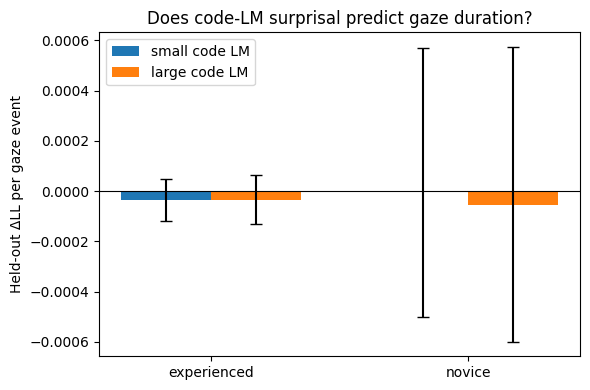

In [11]:
# Figure: surprisal gain by class and model
fig, ax = plt.subplots(figsize=(6, 4))
# Bar positions
x = np.arange(len(CLASSES))
# Draw one bar group per model
for j, key in enumerate(["small", "large"]):
    # Rows for this model in class order
    t = surp_table[surp_table["lm"] == key].set_index("class").loc[CLASSES]
    # Error bars from the bootstrap interval
    err = [t["delta_ll_per_event"] - t["ci_low"], t["ci_high"] - t["delta_ll_per_event"]]
    # Bars
    ax.bar(x + (j - 0.5) * 0.35, t["delta_ll_per_event"], 0.35, yerr=err, capsize=4, label=key + " code LM")
# Axis labels
ax.set_xticks(x); ax.set_xticklabels(CLASSES)
ax.set_ylabel("Held-out ΔLL per gaze event")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Does code-LM surprisal predict gaze duration?")
ax.legend()
# Save and show
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig1_surprisal_by_class.png"), dpi=150); plt.show()

In [12]:
# Names of the behavioural features computed for every window
FEATURES = ["mean_log_dur", "sd_log_dur", "regression", "line_regression", "jump", "refixation", "is_name", "is_litop", "in_main", "mean_surp", "surp_sensitivity", "length"]
# Turn one block of consecutive gaze events into a feature vector
def window_features(w):
    # Correlation between surprisal and duration inside the window (how strongly this reader reacts to surprise)
    sens = np.corrcoef(w["surp_small"], w["log_dur"])[0, 1] if w["surp_small"].std() > 0 and w["log_dur"].std() > 0 else 0.0
    return [w["log_dur"].mean(), w["log_dur"].std(), w["regression"].mean(), w["line_regression"].mean(), np.log1p(w["jump"]).mean(), (w["n_fix"] > 1).mean(), w["is_name"].mean(), w["is_litop"].mean(), w["in_main"].mean(), w["surp_small"].mean(), 0.0 if np.isnan(sens) else sens, w["length"].mean()]
# Build all windows
win_rows = []
# Windows never cross trial boundaries
for (p, t), g in events.groupby(["participant", "trial"]):
    # Number of complete windows in this trial
    for k in range(len(g) // WINDOW):
        # Slice the window
        w = g.iloc[k * WINDOW:(k + 1) * WINDOW]
        # Store participant, class and features
        win_rows.append([p, labels[p]] + window_features(w))
# Window table
windows = pd.DataFrame(win_rows, columns=["participant", "cls"] + FEATURES)
# Windows per developer
wcount = windows.groupby("participant").size()
# Keep developers with enough windows for the largest shot setting
keep = wcount[wcount >= max(SHOTS) + N_QUERY].index
windows = windows[windows["participant"].isin(keep)].reset_index(drop=True)
# Report
print("Windows:", len(windows), "| developers:", windows["participant"].nunique())
print(windows.groupby("cls")["participant"].nunique().to_string())

Windows: 1418 | developers: 98
cls
experienced    77
novice         21


In [13]:
# One label per developer for a stratified split
dev_labels = windows.groupby("participant")["cls"].first()
# 60% of developers for training, 40% unseen developers for testing
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.4, random_state=SEED)
tr_idx, te_idx = next(sss.split(dev_labels.index.values, dev_labels.values))
TRAIN_DEVS = set(dev_labels.index.values[tr_idx]); TEST_DEVS = set(dev_labels.index.values[te_idx])
# Masks for windows
is_tr = windows["participant"].isin(TRAIN_DEVS).values; is_te = windows["participant"].isin(TEST_DEVS).values
# Scaler fitted on training developers only
scaler = StandardScaler().fit(windows.loc[is_tr, FEATURES])
# Standardised features
Z = scaler.transform(windows[FEATURES])
# Learned metric: NCA trained to tell training developers apart from their windows
nca = NeighborhoodComponentsAnalysis(n_components=8, random_state=SEED, max_iter=200).fit(Z[is_tr], windows.loc[is_tr, "participant"].values)
# Embedded windows
E = nca.transform(Z)
# Report the split
print("Train developers:", len(TRAIN_DEVS), "| unseen test developers:", len(TEST_DEVS))

Train developers: 58 | unseen test developers: 40


In [14]:
# N-way K-shot identification of unseen developers, exactly like few-shot character/style recognition
def id_episodes(X, pids, k, rng):
    # Index lists per developer
    by_dev = {p: np.where(pids == p)[0] for p in np.unique(pids)}
    # Developers with enough windows
    devs = [p for p, ix in by_dev.items() if len(ix) >= k + N_QUERY]
    # Accuracy of every episode
    accs = []
    # Repeat random episodes
    for _ in range(N_EPISODES):
        # Choose N developers
        chosen = rng.choice(devs, size=N_WAY, replace=False)
        # Prototypes and queries
        protos, qx, qy = [], [], []
        # Build the support and query sets
        for j, p in enumerate(chosen):
            ix = rng.permutation(by_dev[p])[:k + N_QUERY]
            protos.append(X[ix[:k]].mean(axis=0))
            qx.append(X[ix[k:]]); qy += [j] * N_QUERY
        # Nearest-prototype prediction
        P = np.stack(protos); Q = np.concatenate(qx)
        pred = np.argmin(((Q[:, None, :] - P[None, :, :]) ** 2).sum(-1), axis=1)
        accs.append((pred == np.array(qy)).mean())
    # Mean and normal 95% interval over episodes
    a = np.array(accs)
    return a.mean(), 1.96 * a.std() / np.sqrt(len(a))
# Run for both feature spaces and every shot count
rng = np.random.default_rng(SEED)
id_rows = []
pid_te = windows.loc[is_te, "participant"].values
for k in SHOTS:
    for name, X in [("standardised features", Z[is_te]), ("NCA metric", E[is_te])]:
        m, ci = id_episodes(X, pid_te, k, rng)
        id_rows.append({"space": name, "shots": k, "accuracy": m, "ci95": ci})
# Table
id_table = pd.DataFrame(id_rows)
id_table.to_csv(os.path.join(OUT_DIR, "fewshot_developer_identification.csv"), index=False)
print(f"{N_WAY}-way identification of unseen developers (chance = {1 / N_WAY:.2f})")
print(id_table.round(4).to_string(index=False))

5-way identification of unseen developers (chance = 0.20)
                space  shots  accuracy   ci95
standardised features      1    0.2476 0.0086
           NCA metric      1    0.2807 0.0098
standardised features      3    0.2863 0.0096
           NCA metric      3    0.3219 0.0101
standardised features      5    0.3109 0.0093
           NCA metric      5    0.3453 0.0105


In [15]:
# Random K-window profiles: the "few shots" we observe of a developer
def sample_profiles(df_feats, pids, k, n, rng):
    # Output arrays
    Xs, ps = [], []
    # One block per developer
    for p in np.unique(pids):
        ix = np.where(pids == p)[0]
        # Draw n random K-subsets and average them
        for _ in range(n):
            pick = rng.choice(ix, size=k, replace=False)
            Xs.append(df_feats[pick].mean(axis=0)); ps.append(p)
    return np.array(Xs), np.array(ps)
# Balanced accuracy over unseen developers with a bootstrap interval
def dev_balanced_acc(pred, ps, truth, rng):
    # Accuracy per developer
    acc = pd.Series(pred == truth).groupby(ps).mean()
    # Class of each developer
    cls_of = pd.Series(truth).groupby(ps).first()
    # Mean over classes of per-developer accuracy
    def bal(devs):
        # Plain arrays avoid index alignment problems when developers repeat in a bootstrap sample
        a, k = acc[devs].values, cls_of[devs].values
        return np.mean([a[k == c].mean() for c in CLASSES if (k == c).any()])
    # Bootstrap over developers
    devs = acc.index.values
    boots = [bal(rng.choice(devs, size=len(devs), replace=True)) for _ in range(300)]
    return bal(devs), np.percentile(boots, 2.5), np.percentile(boots, 97.5)
# Arrays for the train and test pools
Ztr, ptr = Z[is_tr], windows.loc[is_tr, "participant"].values
Zte, pte = Z[is_te], windows.loc[is_te, "participant"].values
# Results per shot count
cls_rows = []
for k in SHOTS:
    # Training profiles built from K windows
    Xtr_k, Ptr_k = sample_profiles(Ztr, ptr, k, PROFILE_SAMPLES, rng)
    ytr_k = np.array([labels[p] for p in Ptr_k])
    # Test profiles built from K windows of unseen developers
    Xte_k, Pte_k = sample_profiles(Zte, pte, k, PROFILE_SAMPLES, rng)
    yte_k = np.array([labels[p] for p in Pte_k])
    # Prototype classifier: one mean profile per class (the font-thesis idea)
    protos = {c: Xtr_k[ytr_k == c].mean(axis=0) for c in CLASSES}
    pred_proto = np.array([min(CLASSES, key=lambda c: ((x - protos[c]) ** 2).sum()) for x in Xte_k])
    # Interpretable logistic regression
    lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr_k, ytr_k)
    pred_lr = lr.predict(Xte_k)
    # Score both
    for name, pred in [("class prototypes", pred_proto), ("logistic regression", pred_lr)]:
        m, lo, hi = dev_balanced_acc(pred, Pte_k, yte_k, rng)
        cls_rows.append({"method": name, "shots": k, "balanced_acc": m, "ci_low": lo, "ci_high": hi})
# Table
cls_table = pd.DataFrame(cls_rows)
cls_table.to_csv(os.path.join(OUT_DIR, "fewshot_class_prediction.csv"), index=False)
print("Predicting the class of unseen developers from K windows (chance = 0.50)")
print(cls_table.round(4).to_string(index=False))

Predicting the class of unseen developers from K windows (chance = 0.50)
             method  shots  balanced_acc  ci_low  ci_high
   class prototypes      1        0.4848  0.4160   0.5841
logistic regression      1        0.4980  0.4198   0.5725
   class prototypes      3        0.5058  0.3880   0.6189
logistic regression      3        0.4699  0.4051   0.5563
   class prototypes      5        0.4244  0.3067   0.5609
logistic regression      5        0.4464  0.3672   0.5298


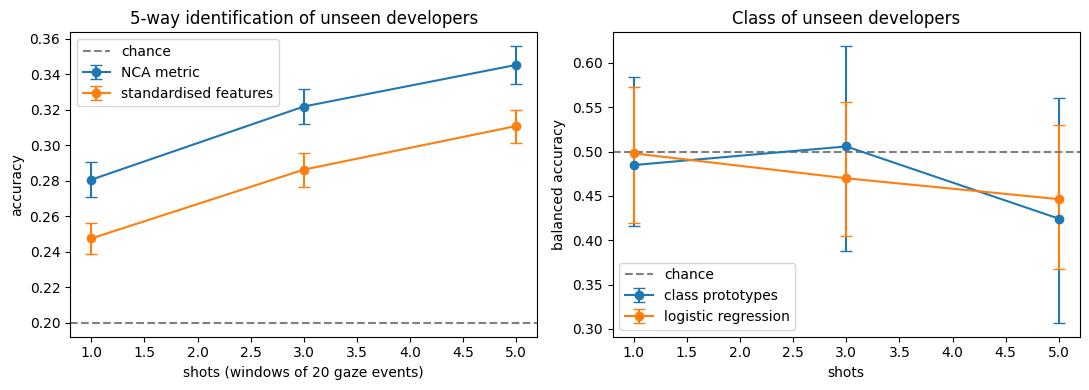

In [16]:
# Figure: identification and class prediction against number of shots
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# Left panel: developer identification
for name, t in id_table.groupby("space"):
    axes[0].errorbar(t["shots"], t["accuracy"], yerr=t["ci95"], marker="o", capsize=4, label=name)
axes[0].axhline(1 / N_WAY, color="grey", linestyle="--", label="chance")
axes[0].set_xlabel("shots (windows of 20 gaze events)"); axes[0].set_ylabel("accuracy")
axes[0].set_title(f"{N_WAY}-way identification of unseen developers"); axes[0].legend()
# Right panel: class prediction
for name, t in cls_table.groupby("method"):
    axes[1].errorbar(t["shots"], t["balanced_acc"], yerr=[t["balanced_acc"] - t["ci_low"], t["ci_high"] - t["balanced_acc"]], marker="o", capsize=4, label=name)
axes[1].axhline(0.5, color="grey", linestyle="--", label="chance")
axes[1].set_xlabel("shots"); axes[1].set_ylabel("balanced accuracy")
axes[1].set_title("Class of unseen developers"); axes[1].legend()
# Save and show
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig2_fewshot.png"), dpi=150); plt.show()

         feature  coef_towards_novice  permutation_importance
         is_name              -1.4002                  0.0306
        is_litop              -0.8168                  0.0013
            jump              -0.7395                  0.0270
surp_sensitivity              -0.7284                  0.0195
 line_regression               0.6596                  0.0102
      sd_log_dur              -0.4958                  0.0107
          length               0.4207                 -0.0108
      regression               0.3540                 -0.0168
      refixation              -0.3269                  0.0065
         in_main               0.2798                  0.0001
    mean_log_dur               0.2581                 -0.0050
       mean_surp               0.2155                 -0.0048

Rule summary (standardised feature units):
|--- refixation <= 0.06
|   |--- mean_log_dur <= 1.22
|   |   |--- class: novice
|   |--- mean_log_dur >  1.22
|   |   |--- class: novice
|--- refixat

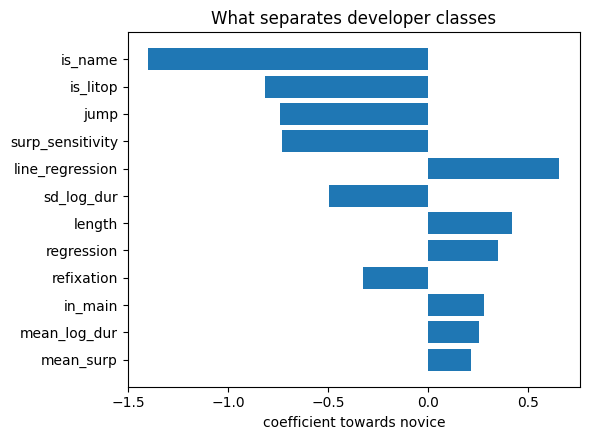

In [17]:
# Interpretable model on 5-shot profiles: why is a developer put in a class?
K_EXPLAIN = max(SHOTS)
# Training and test profiles
Xtr5, Ptr5 = sample_profiles(Ztr, ptr, K_EXPLAIN, PROFILE_SAMPLES, rng)
ytr5 = np.array([labels[p] for p in Ptr5])
Xte5, Pte5 = sample_profiles(Zte, pte, K_EXPLAIN, PROFILE_SAMPLES, rng)
yte5 = np.array([labels[p] for p in Pte5])
# Logistic regression on standardised features (coefficients are directly comparable)
expl_lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr5, ytr5)
# Coefficient table: positive values push towards the second class name
coef = pd.DataFrame({"feature": FEATURES, "coef_towards_" + expl_lr.classes_[1]: expl_lr.coef_[0]})
coef = coef.reindex(coef.iloc[:, 1].abs().sort_values(ascending=False).index)
# Permutation importance on unseen developers (drop in accuracy when a feature is shuffled)
base_acc = (expl_lr.predict(Xte5) == yte5).mean()
perm = []
for j, f in enumerate(FEATURES):
    drops = []
    for _ in range(20):
        Xp = Xte5.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        drops.append(base_acc - (expl_lr.predict(Xp) == yte5).mean())
    perm.append(np.mean(drops))
coef["permutation_importance"] = [perm[FEATURES.index(f)] for f in coef["feature"]]
coef.to_csv(os.path.join(OUT_DIR, "interpretability_coefficients.csv"), index=False)
print(coef.round(4).to_string(index=False))
# Depth-2 decision tree gives human-readable rules
tree = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=SEED).fit(Xtr5, ytr5)
print("\nRule summary (standardised feature units):")
print(export_text(tree, feature_names=FEATURES))
print("Tree accuracy on unseen developers:", round((tree.predict(Xte5) == yte5).mean(), 3))
# Figure of coefficients
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(coef["feature"][::-1], coef.iloc[::-1, 1])
ax.set_xlabel("coefficient towards " + expl_lr.classes_[1]); ax.set_title("What separates developer classes")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig3_interpretability.png"), dpi=150); plt.show()

In [18]:
# Explain one prediction for one unseen developer in plain words
def explain_developer(p, k, rng):
    # Windows of this developer
    ix = np.where(pte == p)[0]
    # Random K shots
    pick = rng.choice(ix, size=k, replace=False)
    # Their profile
    x = Zte[pick].mean(axis=0)
    # Predicted class and probability
    proba = expl_lr.predict_proba(x[None])[0]
    pred = expl_lr.classes_[int(np.argmax(proba))]
    # Contribution of every feature to the decision
    contrib = pd.Series(expl_lr.coef_[0] * x, index=FEATURES).sort_values(key=np.abs, ascending=False)
    return pred, float(proba.max()), contrib
# Pick the first unseen developer
demo_dev = sorted(TEST_DEVS)[0]
demo_pred, demo_conf, demo_contrib = explain_developer(demo_dev, K_EXPLAIN, rng)
# Print the explanation
print(f"Developer {demo_dev} | true class: {labels[demo_dev]} | predicted from {K_EXPLAIN} shots: {demo_pred} (p = {demo_conf:.2f})")
print("Top reasons (positive pushes towards", expl_lr.classes_[1] + "):")
print(demo_contrib.head(4).round(3).to_string())

Developer 6 | true class: experienced | predicted from 5 shots: experienced (p = 0.68)
Top reasons (positive pushes towards novice):
surp_sensitivity    0.409
sd_log_dur         -0.338
line_regression    -0.215
jump                0.208


In [19]:
# Fitted reading-cost model per class: predicted gaze duration from length and the class-matched surprisal
COST_MODEL = {}
for c in CLASSES:
    # Events of this class
    sub = events[events["cls"] == c]
    # Matched model for this class
    sc = "surp_" + MATCHED_LM[c]
    # Absolute log duration regression: intercept, length, surprisal
    X = np.column_stack([np.ones(len(sub)), sub["length"].values, sub[sc].values])
    COST_MODEL[c] = ols_fit(X, sub["log_dur"].values)
    print(c, "| log_dur = %.3f + %.3f*length + %.3f*surprisal" % tuple(COST_MODEL[c]), "| listener LM:", MATCHED_LM[c])
# Load the speaker model (instruction-tuned) for Part 2
SPEAKER = load_lm(SPEAKER_LM)
print("Speaker loaded:", SPEAKER_LM)

experienced | log_dur = 4.848 + 0.029*length + 0.003*surprisal | listener LM: small
novice | log_dur = 4.839 + 0.026*length + 0.002*surprisal | listener LM: small


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Speaker loaded: Qwen/Qwen2.5-Coder-1.5B-Instruct


In [20]:
# Questions per program; the expected answer string is used to check correctness (None = open question)
QUESTIONS = {
    "rectangle": [("What does this program print, and why?", ["100", "25"]), ("What does each of the methods width(), height() and area() compute?", None), ("What is the area of rect2, and how is it computed?", ["25"])],
    "vehicle": [("What is the value of currentSpeed after main runs, and why?", ["10"]), ("Explain what the accelerate() method does.", None), ("If main called v.accelerate(250) instead, what would it return, and why?", ["200"])],
}
# Explanation styles the speaker can produce (the RSA alternatives)
STYLES = {
    "concise": "Answer in two or three sentences for an experienced Java developer. Skip the basics.",
    "stepwise": "Explain step by step for a beginner who is new to Java. Briefly define each term you use.",
    "trace": "Walk through the relevant lines in order, cite line numbers, and show the intermediate values.",
    "analogy": "Start with one everyday analogy, then give the precise answer about the code.",
}
# Background notes used by retrieval (a tiny knowledge base)
NOTES = [
    "A constructor has the same name as the class and initialises the fields of a new object.",
    "The keyword this refers to the current object, so this.x1 is the field x1 of that object.",
    "A method with return type int returns an integer; a method with return type double returns a floating-point number.",
    "System.out.println prints its argument followed by a newline; a double value such as 100 is printed as 100.0.",
    "An if-else statement runs the first block when the condition is true and the else block otherwise.",
    "Integer subtraction this.x2 - this.x1 gives the distance between two coordinates.",
]
# Few-shot demonstrations about unrelated classes; their identifiers let us measure leakage
FEWSHOT = [
    ("class Circle { double radius; Circle(double r) { radius = r; } double getArea() { return Math.PI * radius * radius; } }", "What does getArea() return?", "getArea() returns the area of the circle, computed as Math.PI times radius squared. For radius 2 it returns about 12.57."),
    ("class BankAccount { int balance; void deposit(int amount) { balance = balance + amount; } }", "What does deposit() do?", "deposit() adds amount to the field balance. After deposit(50) on a new account, balance is 50."),
]
# Identifiers that only exist in the demonstrations
LEAK_IDS = {"Circle", "radius", "getArea", "BankAccount", "balance", "deposit", "amount", "PI"}
# Number each code line so the model can cite lines
def numbered(code):
    return "\n".join(f"{i + 1:2d}: {l}" for i, l in enumerate(code.split("\n")))
# Retrieval over code lines and notes with TF-IDF
def retrieve(prog, question, k=6):
    # Documents: each numbered code line plus each note
    docs = [f"line {i + 1}: {l.strip()}" for i, l in enumerate(PROGRAMS[prog].split("\n")) if l.strip() not in ("{", "}")] + NOTES
    # Identifier-aware tokenisation
    vec = TfidfVectorizer(token_pattern=r"[A-Za-z_][A-Za-z0-9_]*|\d+", lowercase=True).fit(docs + [question])
    # Similarity between question and documents
    sims = cosine_similarity(vec.transform([question]), vec.transform(docs))[0]
    # Best k documents in their original order
    top = sorted(np.argsort(-sims)[:k])
    return [docs[i] for i in top]
# Build the user prompt for one condition
def build_prompt(prog, question, style, grounding):
    # Base prompt always contains the full program
    text = f"Java program:\n{numbered(PROGRAMS[prog])}\n\nQuestion: {question}\n"
    # Retrieval-augmented grounding adds relevant lines, notes and a faithfulness instruction
    if grounding == "rag":
        text += "\nRelevant lines and notes:\n" + "\n".join("- " + d for d in retrieve(prog, question)) + "\n"
        text += "Only mention identifiers and values that appear in the program above.\n"
    # Style instruction
    text += f"\nInstructions: {STYLES[style]}"
    return text
# Turn a prompt (plus optional demonstrations) into model input text
def chat_text(user_prompt, shots):
    # Conversation history
    msgs = []
    # Add demonstrations as earlier turns
    for code, q, a in FEWSHOT[:shots]:
        msgs.append({"role": "user", "content": f"Java program:\n{code}\n\nQuestion: {q}"})
        msgs.append({"role": "assistant", "content": a})
    # Final user turn
    msgs.append({"role": "user", "content": user_prompt})
    # Use the model's chat template when it has one
    if getattr(SPEAKER["tok"], "chat_template", None):
        return SPEAKER["tok"].apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    # Plain fallback format
    return "".join(f"{m['role'].capitalize()}: {m['content']}\n" for m in msgs) + "Assistant:"
# Greedy generation (deterministic, so results are reproducible)
def generate(text):
    # Tokenise without extra special tokens (the template already has them)
    enc = SPEAKER["tok"](text, return_tensors="pt", add_special_tokens=False)
    ids = enc["input_ids"].to(DEVICE); mask = enc["attention_mask"].to(DEVICE)
    # Decode new tokens only
    with torch.no_grad():
        out = SPEAKER["model"].generate(input_ids=ids, attention_mask=mask, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=SPEAKER["tok"].pad_token_id)
    return SPEAKER["tok"].decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()
# Print one example prompt
print(build_prompt("rectangle", QUESTIONS["rectangle"][0][0], "concise", "rag"))

Java program:
 1: public class Rectangle {
 2:     private int x1, y1, x2, y2;
 3:     public Rectangle(int x1, int y1, int x2, int y2) {
 4:         this.x1 = x1;
 5:         this.y1 = y1;
 6:         this.x2 = x2;
 7:         this.y2 = y2;
 8:     }
 9:     public int width() { return this.x2 - this.x1; }
10:     public int height() { return this.y2 - this.y1; }
11:     public double area() { return this.width() * this.height(); }
12:     public static void main(String[] args) {
13:         Rectangle rect1 = new Rectangle(0, 0, 10, 10);
14:         System.out.println(rect1.area());
15:         Rectangle rect2 = new Rectangle(5, 5, 10, 10);
16:         System.out.println(rect2.area());
17:     }
18: }

Question: What does this program print, and why?

Relevant lines and notes:
- line 4: this.x1 = x1;
- line 9: public int width() { return this.x2 - this.x1; }
- line 10: public int height() { return this.y2 - this.y1; }
- line 11: public double area() { return this.width() * this.height

In [21]:
# Generate every candidate: program x question x style x grounding x demonstrations
cands = []
# Timer for the whole grid
t0 = time.time()
for prog, qs in QUESTIONS.items():
    for qi, (question, answer) in enumerate(qs):
        for grounding in ["plain", "rag"]:
            for shots in [0, 2]:
                for style in STYLES:
                    # Build input and generate
                    text = generate(chat_text(build_prompt(prog, question, style, grounding), shots))
                    # Store the candidate
                    cands.append({"program": prog, "qid": qi, "question": question, "answer": answer, "grounding": grounding, "shots": shots, "style": style, "explanation": text})
# Candidate table
cands = pd.DataFrame(cands)
# Save raw generations
cands.to_csv(os.path.join(OUT_DIR, "candidate_explanations.csv"), index=False)
print("Generated", len(cands), "explanations in", round(time.time() - t0, 1), "s")
print(cands.iloc[0]["explanation"][:500])

Generated 96 explanations in 589.6 s
This program prints `100` and `25`. The reason is that the `area()` method calculates the area of the rectangle by subtracting the width from the height and then multiplying the result by the width again. In the first rectangle (`rect1`), the width is `10` and the height is `10`, so the area is `10 * 10 = 100`. In the second rectangle (`rect2`), the width is also `10` and the height is `10`, so the area is `10 * 10 = 25`.


In [22]:
# Java words and API names that are not hallucinations
JAVA_OK = {"public", "private", "static", "void", "int", "double", "String", "class", "new", "return", "this", "if", "else", "System", "out", "println", "main", "args", "Java", "java", "true", "false", "null", "Math"}
# Identifiers defined in each program
CODE_IDS = {p: set(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", c)) for p, c in PROGRAMS.items()}
# Code-like identifiers mentioned in an explanation
def mentioned_ids(text):
    ids = set()
    # Anything inside backticks
    for m in re.findall(r"`([^`]+)`", text):
        ids.update(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", m))
    # Names written as calls, for example area()
    ids.update(re.findall(r"\b([A-Za-z_][A-Za-z0-9_]*)\(", text))
    # Fields written as this.name
    ids.update(re.findall(r"\bthis\.([A-Za-z_][A-Za-z0-9_]*)", text))
    # camelCase, snake_case or letter+digit names
    for w in re.findall(r"\b[A-Za-z_][A-Za-z0-9_]*\b", text):
        if re.search(r"[a-z][A-Z]", w) or "_" in w or re.search(r"[A-Za-z]\d", w):
            ids.add(w)
    return ids
# Faithfulness and correctness metrics for one explanation
def faithfulness(row):
    # Identifiers mentioned
    ids = mentioned_ids(row["explanation"])
    # Allowed names: program identifiers, Java words and words from the question
    allowed = CODE_IDS[row["program"]] | JAVA_OK | set(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", row["question"]))
    # Unsupported identifiers
    bad = ids - allowed
    # Leakage from the demonstrations
    leak = any(re.search(r"\b" + re.escape(w) + r"\b", row["explanation"]) for w in LEAK_IDS)
    # Correctness when an expected answer exists
    correct = np.nan if not isinstance(row["answer"], list) else float(all(re.search(r"\b" + a + r"(\.0)?\b", row["explanation"]) for a in row["answer"]))
    return pd.Series({"n_ids": len(ids), "n_hallucinated": len(bad), "hallucinated": ", ".join(sorted(bad)), "any_hallucination": float(len(bad) > 0), "leakage": float(leak), "correct": correct, "n_words": len(row["explanation"].split())})
# Add the metrics
cands = pd.concat([cands, cands.apply(faithfulness, axis=1)], axis=1)
# Informativity: how much an explanation raises each listener's probability of the program (nats)
base_lp = {(p, k): continuation_logprob(LMS[k], "Java program:\n", PROGRAMS[p]) for p in PROGRAMS for k in LMS}
for k in LMS:
    cands["inf_" + k] = [continuation_logprob(LMS[k], "Explanation: " + e[:1200] + "\n\nJava program:\n", PROGRAMS[p]) - base_lp[(p, k)] for e, p in zip(cands["explanation"], cands["program"])]
# Reading cost (seconds) for each class from its fitted gaze model
def reading_cost(text, c):
    # Word spans
    spans = [(m.start(), m.end()) for m in re.finditer(r"\S+", text)]
    # Empty text costs nothing
    if not spans:
        return 0.0
    # Word surprisal under the class-matched listener
    surp = span_surprisal(subword_surprisal(LMS[MATCHED_LM[c]], "Explanation: ", text), spans)
    # Word lengths without punctuation
    lens = [len(re.sub(r"[^\w]", "", text[a:b])) for a, b in spans]
    # Predicted gaze duration per word, summed and converted to seconds
    b0, b1, b2 = COST_MODEL[c]
    return float(np.sum(np.exp(b0 + b1 * np.array(lens) + b2 * np.nan_to_num(np.array(surp))))) / 1000.0
for c in CLASSES:
    cands["cost_" + c] = [reading_cost(e, c) for e in cands["explanation"]]
# Save scored candidates
cands.to_csv(os.path.join(OUT_DIR, "candidate_explanations_scored.csv"), index=False)
print(cands[["program", "qid", "grounding", "shots", "style", "n_words", "any_hallucination", "leakage", "correct", "inf_small", "inf_large"] + ["cost_" + c for c in CLASSES]].head(8).round(2).to_string(index=False))

  program  qid grounding  shots    style  n_words  any_hallucination  leakage  correct  inf_small  inf_large  cost_experienced  cost_novice
rectangle    0     plain      0  concise       82                0.0      0.0      1.0      11.07      12.10             11.74        11.48
rectangle    0     plain      0 stepwise      113                0.0      0.0      0.0      21.09      18.66             16.67        16.27
rectangle    0     plain      0    trace      111                1.0      0.0      0.0      13.18      18.51             16.38        15.97
rectangle    0     plain      0  analogy      122                0.0      0.0      0.0      13.98      21.15             17.62        17.22
rectangle    0     plain      2  concise       28                0.0      0.0      1.0      11.79      11.80              4.12         4.01
rectangle    0     plain      2 stepwise      112                0.0      0.0      0.0      21.03      24.59             16.13        15.77
rectangle    0     p

grounding  shots            metric  rate  ci_low  ci_high  n
    plain      0 any_hallucination 0.208   0.083    0.375 24
    plain      0           leakage 0.167   0.042    0.333 24
    plain      0           correct 0.562   0.312    0.812 16
    plain      2 any_hallucination 0.042   0.000    0.125 24
    plain      2           leakage 0.000   0.000    0.000 24
    plain      2           correct 0.812   0.625    1.000 16
      rag      0 any_hallucination 0.083   0.000    0.208 24
      rag      0           leakage 0.125   0.000    0.292 24
      rag      0           correct 0.562   0.312    0.812 16
      rag      2 any_hallucination 0.167   0.042    0.333 24
      rag      2           leakage 0.042   0.000    0.125 24
      rag      2           correct 0.688   0.438    0.875 16

Effect of 2 demonstrations on hallucination: -0.042 (paired permutation p = 0.725, n = 48 pairs)


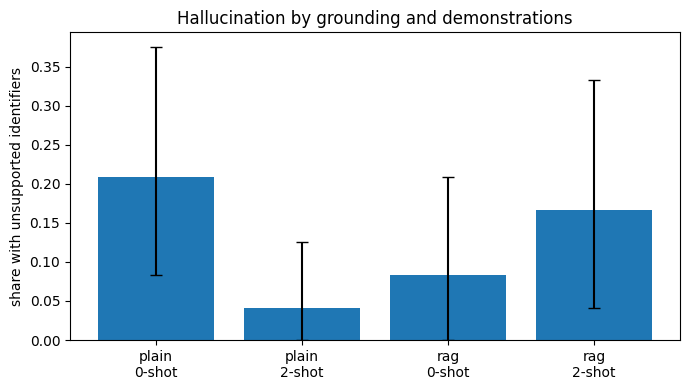

In [23]:
# Faithfulness by grounding and demonstrations (the POPE-style question applied to code explanations)
def rate_ci(v):
    v = np.asarray(v, dtype=float); v = v[~np.isnan(v)]
    return boot_ci(v) if len(v) else (np.nan, np.nan, np.nan)
hal_rows = []
for (g, s), t in cands.groupby(["grounding", "shots"]):
    for metric in ["any_hallucination", "leakage", "correct"]:
        m, lo, hi = rate_ci(t[metric])
        hal_rows.append({"grounding": g, "shots": s, "metric": metric, "rate": m, "ci_low": lo, "ci_high": hi, "n": int(t[metric].notna().sum())})
hal_table = pd.DataFrame(hal_rows)
hal_table.to_csv(os.path.join(OUT_DIR, "faithfulness_by_condition.csv"), index=False)
print(hal_table.round(3).to_string(index=False))
# Paired permutation test: do demonstrations change the hallucination rate (same program, question, style, grounding)?
pair = cands.pivot_table(index=["program", "qid", "grounding", "style"], columns="shots", values="any_hallucination").dropna()
diff = (pair[2] - pair[0]).values
obs = diff.mean()
perm_stats = [(diff * rng.choice([-1, 1], size=len(diff))).mean() for _ in range(5000)]
p_val = float((np.abs(perm_stats) >= abs(obs) - 1e-12).mean())
print(f"\nEffect of 2 demonstrations on hallucination: {obs:+.3f} (paired permutation p = {p_val:.3f}, n = {len(diff)} pairs)")
# Figure
fig, ax = plt.subplots(figsize=(7, 4))
t = hal_table[hal_table["metric"] == "any_hallucination"]
labels_x = [f"{g}\n{s}-shot" for g, s in zip(t["grounding"], t["shots"])]
ax.bar(labels_x, t["rate"], yerr=[t["rate"] - t["ci_low"], t["ci_high"] - t["rate"]], capsize=4)
ax.set_ylabel("share with unsupported identifiers"); ax.set_title("Hallucination by grounding and demonstrations")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig4_hallucination.png"), dpi=150); plt.show()

In [24]:
# RSA pragmatic speaker: utility = listener informativity - alpha * class-specific reading cost
def rsa_choose(group, c, alpha):
    # Informativity under the class-matched listener
    inf = group["inf_" + MATCHED_LM[c]].values
    # Reading cost under the class gaze model
    cost = group["cost_" + c].values
    # Utility of every alternative
    util = inf - alpha * cost
    # Softmax speaker probabilities
    pr = np.exp(RSA_LAMBDA * (util - util.max())); pr = pr / pr.sum()
    # Most probable explanation
    i = int(np.argmax(pr))
    return group.iloc[i], float(pr[i])
# Main condition: retrieval grounding without demonstrations
main = cands[(cands["grounding"] == "rag") & (cands["shots"] == 0)]
rsa_rows = []
for c in CLASSES:
    for (prog, qi), g in main.groupby(["program", "qid"]):
        # Pragmatic choice, literal choice (alpha = 0) and two fixed styles as baselines
        choices = {"RSA (alpha=%.2g)" % MAIN_ALPHA: rsa_choose(g, c, MAIN_ALPHA)[0], "literal (alpha=0)": rsa_choose(g, c, 0.0)[0], "always concise": g[g["style"] == "concise"].iloc[0], "always stepwise": g[g["style"] == "stepwise"].iloc[0]}
        for policy, r in choices.items():
            rsa_rows.append({"class": c, "policy": policy, "program": prog, "qid": qi, "style": r["style"], "inf": r["inf_" + MATCHED_LM[c]], "cost_s": r["cost_" + c], "n_words": r["n_words"], "hallucination": r["any_hallucination"], "correct": r["correct"]})
rsa_table = pd.DataFrame(rsa_rows)
rsa_table.to_csv(os.path.join(OUT_DIR, "rsa_choices.csv"), index=False)
# Summary per class and policy
rsa_summary = rsa_table.groupby(["class", "policy"]).agg(inf=("inf", "mean"), cost_s=("cost_s", "mean"), words=("n_words", "mean"), hallucination=("hallucination", "mean"), correct=("correct", "mean")).reset_index()
print(rsa_summary.round(3).to_string(index=False))
print("\nStyles chosen by RSA per class:")
print(rsa_table[rsa_table["policy"].str.startswith("RSA")].groupby("class")["style"].value_counts().to_string())

      class            policy    inf  cost_s   words  hallucination  correct
experienced     RSA (alpha=1) 47.854  14.153  96.500          0.167      0.5
experienced    always concise 21.884   8.845  60.167          0.000      1.0
experienced   always stepwise 37.686  16.043 108.500          0.167      0.5
experienced literal (alpha=0) 48.330  16.105 109.167          0.000      0.5
     novice     RSA (alpha=1) 47.854  13.802  96.500          0.167      0.5
     novice    always concise 21.884   8.623  60.167          0.000      1.0
     novice   always stepwise 37.686  15.644 108.500          0.167      0.5
     novice literal (alpha=0) 48.330  15.704 109.167          0.000      0.5

Styles chosen by RSA per class:
class        style   
experienced  trace       4
             stepwise    2
novice       trace       4
             stepwise    2


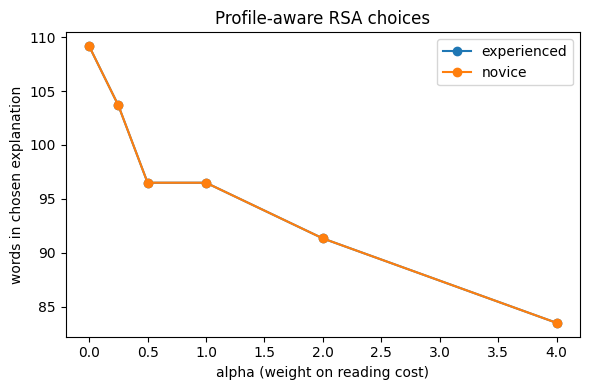

      class  alpha  mean_words  share_stepwise
experienced   0.00     109.167           0.333
experienced   0.25     103.667           0.333
experienced   0.50      96.500           0.333
experienced   1.00      96.500           0.333
experienced   2.00      91.333           0.333
experienced   4.00      83.500           0.167
     novice   0.00     109.167           0.333
     novice   0.25     103.667           0.333
     novice   0.50      96.500           0.333
     novice   1.00      96.500           0.333
     novice   2.00      91.333           0.333
     novice   4.00      83.500           0.167


In [25]:
# Sensitivity: how the chosen explanation length changes with alpha for each class
sweep = []
for c in CLASSES:
    for a in ALPHAS:
        picks = [rsa_choose(g, c, a)[0] for _, g in main.groupby(["program", "qid"])]
        sweep.append({"class": c, "alpha": a, "mean_words": np.mean([p["n_words"] for p in picks]), "share_stepwise": np.mean([p["style"] == "stepwise" for p in picks])})
sweep = pd.DataFrame(sweep)
sweep.to_csv(os.path.join(OUT_DIR, "rsa_alpha_sweep.csv"), index=False)
fig, ax = plt.subplots(figsize=(6, 4))
for c, t in sweep.groupby("class"):
    ax.plot(t["alpha"], t["mean_words"], marker="o", label=c)
ax.set_xlabel("alpha (weight on reading cost)"); ax.set_ylabel("words in chosen explanation")
ax.set_title("Profile-aware RSA choices"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig5_rsa_alpha.png"), dpi=150); plt.show()
print(sweep.round(3).to_string(index=False))

In [26]:
# End-to-end demo: a new developer -> few-shot profile -> class -> tailored, grounded explanation
print(f"Unseen developer {demo_dev}: predicted class '{demo_pred}' from {K_EXPLAIN} windows (true: {labels[demo_dev]})")
# Rectangle question 0 under retrieval grounding
g = main[(main["program"] == "rectangle") & (main["qid"] == 0)]
# Pragmatic choice for the predicted class
choice, prob = rsa_choose(g, demo_pred, MAIN_ALPHA)
print(f"RSA picks style '{choice['style']}' (speaker probability {prob:.2f}); unsupported identifiers: {choice['hallucinated'] or 'none'}\n")
print(choice["explanation"])

Unseen developer 6: predicted class 'experienced' from 5 windows (true: experienced)
RSA picks style 'stepwise' (speaker probability 0.88); unsupported identifiers: none

Let's walk through the execution of this Java program step-by-step:

The program defines a `Rectangle` class with four integer fields: `x1`, `y1`, `x2`, and `y2`. The constructor initializes these fields with the provided values. The `width()` method calculates the width of the rectangle by subtracting `x1` from `x2`. Similarly, the `height()` method calculates the height by subtracting `y1` from `y2`.

In the `main` method, two `Rectangle` objects are created: `rect1` with coordinates (0, 0) and (10, 10), and `rect2` with coordinates (5, 5) and (10, 10). The `area()` method is called on each rectangle to calculate its area. Since both rectangles have the same dimensions (


In [27]:
# Collect the headline numbers in one file for the proposal
summary = {
    "label_source": LABEL_SOURCE,
    "n_developers_with_windows": int(windows["participant"].nunique()),
    "matched_listener_lm": MATCHED_LM,
    "surprisal_fit": surp_table.round(5).to_dict(orient="records"),
    "developer_identification": id_table.round(4).to_dict(orient="records"),
    "class_prediction": cls_table.round(4).to_dict(orient="records"),
    "faithfulness": hal_table.round(4).to_dict(orient="records"),
    "demonstration_effect_on_hallucination": {"mean_difference": round(float(obs), 4), "permutation_p": round(p_val, 4), "pairs": int(len(diff))},
    "rsa_summary": rsa_summary.round(4).to_dict(orient="records"),
}
# Write JSON
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=str)
# List everything that was saved
print("Saved files:")
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f)

Saved files:
 - candidate_explanations.csv
 - candidate_explanations_scored.csv
 - faithfulness_by_condition.csv
 - fewshot_class_prediction.csv
 - fewshot_developer_identification.csv
 - fig1_surprisal_by_class.png
 - fig2_fewshot.png
 - fig3_interpretability.png
 - fig4_hallucination.png
 - fig5_rsa_alpha.png
 - interpretability_coefficients.csv
 - rsa_alpha_sweep.csv
 - rsa_choices.csv
 - summary.json
 - surprisal_fit_by_class.csv
